In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision

from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.models import resnet50, vgg16
from torchvision.datasets.imagenet import ImageNet, parse_devkit_archive
from tqdm import tqdm
from PIL import Image

from src.CIBISA import *
from src.CIBISA_utils import *
from src.models import *

In [2]:
def train_bottleneck_sal(model, x, y, flag, epochs, loss_ce, loss_inf, opt):
    sals = []
    for i in range(epochs):
        opt.zero_grad()
        y_pred = model(x)

        sals.append(model.get_saliency().detach().cpu().numpy())
        
        loss = loss_ce(y_pred, y, flag) + loss_inf(model.get_saliency())
        loss.backward(retain_graph=True)

        opt.step()                

    return model.get_saliency().detach().cpu().numpy(), sals

In [3]:

def compute_saliency_sal(x:torch.Tensor, x_target:torch.Tensor, model, loss_mode='cosine_sim', return_negative:bool=False, n_masks:int=20, epochs:int=15, beta:int=10, learnable_param=False) -> np.array:
    # computing the target embedding
    k = 3*224*224
    with torch.enable_grad():
        if model._get_name() == 'CLIP' or model._get_name() == 'CLIPModel':
            assert x_target.shape == (1,512), "When using the CLIP model, you should pass the text/image embedding of shape (1,512) as target"
            y_target = x_target
        else:
            y_target = model(x_target)

        # setting the flag for computing positive/negative relations
        if return_negative:
            y_flag = -torch.ones(1, dtype=torch.long, device=device)
        else:
            y_flag = torch.ones(1, dtype=torch.long, device=device)

        # defining the bottleneck layer
        ms = int(np.ceil(x.shape[-1]/32))
        new_layer = InfoLayer(mask_range=3, mask_size=ms, input_size=x.shape[-1])
        new_layer = new_layer.to(device=device)

        # placing the bottleneck in the target model
        new_core = InfoModel(core=model, bottleneck=new_layer)
        new_core = new_core.to(device=device)

        # losses and parameters
        P = list(new_core.parameters())

        if learnable_param:
            loss_inf = InfoLoss(learnable_param=learnable_param).to(device)
            loss_sim = SimilarityLoss(mode=loss_mode, sigma=1, learnable_param=False).to(device)

            P.extend(list(loss_inf.parameters()))
            P.extend(list(loss_sim.parameters()))

            optimizer = torch.optim.Adam(P, lr=1)

        else:
            loss_inf = InfoLoss(beta=beta/k, phi=1/k).to(device)
            loss_sim = SimilarityLoss(mode=loss_mode, sigma=1).to(device)
            optimizer = torch.optim.Adam(P, lr=1)
            
        # computing the saliency
        final_saliency = 0
        hyperparams = []
        for _ in range(n_masks):
            new_core.reset_model()

            if learnable_param:
                loss_inf.reset_loss()
            
            saliency, hps = train_bottleneck_sal(model=new_core, x=x, y=y_target, flag=y_flag, loss_ce=loss_sim, loss_inf=loss_inf, opt=optimizer, epochs=epochs)
            final_saliency +=  saliency
            hyperparams.append(hps)

        final_saliency = np.squeeze(final_saliency)
        final_saliency = (final_saliency - np.min(final_saliency))/(np.max(final_saliency) - np.min(final_saliency))

    return final_saliency, hyperparams

In [4]:
if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')

torch.manual_seed(0)

transform = torchvision.transforms.Compose([torchvision.transforms.Resize((224,224)),
                            torchvision.transforms.ToTensor()])

In [5]:
architecture = 'ResNET'

if architecture == 'VGG':
    model = VGG_emb()
    model = model.to(device)
    model.eval()
elif architecture == 'ResNET':
    model = ResNET_emb()
    model = model.to(device)
    model.eval()
elif architecture == 'ViT':
    model = ViT16_emb()
    model = model.to(device)
    model.eval()
elif architecture == 'Dino':
    model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
    model = model.to(device)
    model.eval()
elif architecture == 'DINOv1':
    model = torch.hub.load('facebookresearch/dino:main', 'dino_resnet50')
    model = model.to(device)
    model.eval()
elif architecture == 'iBOT':
    model = ViT16_emb(weights='iBOT')
    model = model.to(device)
    model.eval()


In [6]:
pil_img1 = Image.open('./test_images/Humming1.JPEG').convert('RGB')
pil_img2 = Image.open('./test_images/Humming2.JPEG').convert('RGB')

img1 = transform(pil_img1)
img2 = transform(pil_img2)

x1 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img1)
x2 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img2)

x1 = x1[None,...].to(device)
x2 = x2[None,...].to(device)

In [7]:
saliency_list = []

s,h = compute_saliency_sal(x=x1, x_target=x2, model=model, n_masks=20, epochs=15, beta=10, return_negative=False, learnable_param=True)

saliency_list.append(h)
saliency_list = saliency_list[0] 

In [8]:
mean_mutual_list_img = []
mean_logits_list_img = []

mean_mutual_list_emb = []
mean_logits_list_emb = []

# step_list = [0, 3, 5, 9]
# for step in step_list:
#     saliency = saliency_list[0][step]
#     # saliency = np.squeeze(saliency.detach().cpu().numpy())

#     img_mask = img*saliency*255
#     img_mask = torch.tensor(img_mask, dtype=torch.uint8)

#     pil_img_mask = transforms.functional.to_pil_image(torch.squeeze(img_mask))
            
#     plt.figure(frameon=False)
#     plt.axes([0,0,1,1])
#     plt.imshow(pil_img_mask, aspect='auto')
#     plt.axis('off')
#     plt.savefig('./out/mutual information/beta' + str(beta) + 'k/' + architecture + '_saliency_beta' + str(beta) + 'k_step_'+ str(step) + '.png')
#     plt.close()

# final_saliency = torch.tensor([0])
# for i in range(len(saliency_list)):
#     s = saliency_list[i][-1]
#     final_saliency = final_saliency + s

# final_saliency = final_saliency.detach().cpu().numpy()
# plt.figure(frameon=False)
# plt.axes([0,0,1,1])
# plt.imshow(pil_img.resize((224,224)), aspect='auto')
# plt.imshow(np.squeeze(final_saliency), cmap='jet', alpha=0.4, aspect='auto')
# plt.axis('off')
# plt.savefig('./out/mutual information/beta' + str(beta) + 'k/'+ architecture + '_final_saliency_beta' + str(beta) + 'k.png')
# plt.close()

mutual_img = np.zeros((20,15))
mutual_emb = np.zeros((20,15))
for i in range(len(saliency_list)):
    for j in range(len(saliency_list[0])):
        saliency = saliency_list[i][j]
        # saliency = np.squeeze(saliency.detach().cpu().numpy())
        hist_img, _, _ = np.histogram2d(x1.ravel(), (x1*saliency).ravel(), bins = 150) 
        hist_emb, _, _ = np.histogram2d(model(x2).ravel(), model(x1*saliency).ravel(), bins = 150) 
        mutual_img[i,j] = mutual_information(hist_img)
        mutual_emb[i,j] = mutual_information(hist_emb)

mean_mutual_img = np.mean(mutual_img, axis=0)
std_mutual_img = np.std(mutual_img, axis=0)

mean_mutual_emb = np.mean(mutual_emb, axis=0)
std_mutual_emb = np.std(mutual_emb, axis=0)

mean_mutual_list_img.append(mean_mutual_img)
mean_mutual_list_emb.append(mean_mutual_emb)

# logits = np.array(logit_list)
# mean_logits = np.mean(logits, axis=0)    
# mean_logits = np.concatenate((preds[0,y].detach().cpu().numpy(), mean_logits))
# mean_logits = mean_logits/np.max(logits)    

# mean_logits_list.append(mean_logits)       

/tmp/ipykernel_42391/747707435.py:44: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  hist_img, _, _ = np.histogram2d(x1.ravel(), (x1*saliency).ravel(), bins = 150)
/tmp/ipykernel_42391/747707435.py:45: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  hist_emb, _, _ = np.histogram2d(model(x2).ravel(), model(x1*saliency).ravel(), bins = 150)


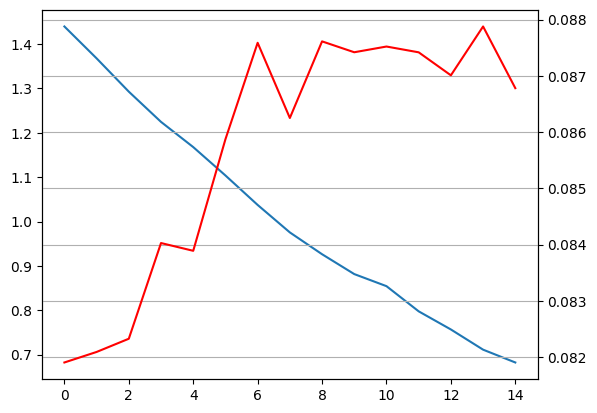

In [15]:
fig, ax1 = plt.subplots()
ax1.plot(mean_mutual_img)

ax2 = ax1.twinx()

ax2.plot(mean_mutual_emb, color='r')
plt.grid()
plt.show()


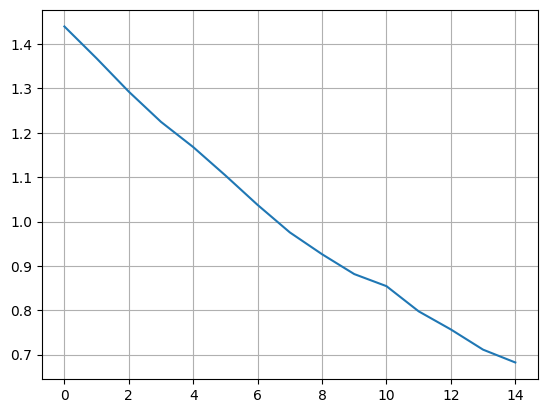

In [9]:
plt.plot(mean_mutual_img)
plt.grid()
# plt.plot(mean_mutual_emb)
# plt.ylim([0, 0.1])

In [10]:
mutual_emb[17,:]

array([0.08763865, 0.08586947, 0.08403025, 0.08673582, 0.08738915,
       0.08344748, 0.08603279, 0.08805936, 0.08517357, 0.08280971,
       0.08178517, 0.08522712, 0.07889282, 0.08239025, 0.07999722])

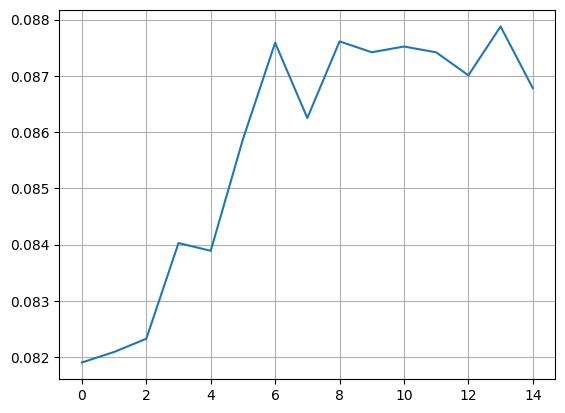

In [11]:
plt.plot(mean_mutual_emb)
plt.grid()

In [12]:
mean_mutual_emb

array([0.08190382, 0.08209095, 0.0823258 , 0.08402681, 0.0838889 ,
       0.0858716 , 0.08758627, 0.08624943, 0.08761145, 0.0874181 ,
       0.08751992, 0.08741692, 0.08700815, 0.08787631, 0.08678005])